<a href="https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-1/07-clasificacion-creditos/clase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Episodio 1.7 · Clasificación: ¿qué crédito revisamos primero?

**Serie:** Del Excel al Machine Learning · **Temporada 1** · 🎬 Video próximamente

## 🎯 Qué vas a aprender

- La diferencia entre predecir un **número** y una **categoría**.
- Entrenar una **regresión logística**, que entrega una probabilidad.
- Usar un **umbral** para pasar de una probabilidad a una decisión.
- Qué significa, y qué no, usar un modelo así en la oficina.

## 📊 En Excel lo harías así

Cobranzas no puede llamar a todos, y quiere revisar primero las ventas al crédito con más riesgo. En Excel:

`=SI(tasa_de_mora_previa>=30%, "Revisar", "OK")`, que en inglés es `IF`.

Es una regla razonable, escrita a mano. Hoy dejamos que un modelo combine varios datos y entregue una **probabilidad** para cada venta.

## 🐍 En Python

### Paso 1: los datos

`creditos.csv` tiene una fila por compra al crédito. El objetivo es `moroso`: 1 si se pagó con más de 30 días de atraso tras vencer el plazo. Antes predecíamos un monto. Ahora, una de dos respuestas. Eso se llama **clasificación**.

> ⚠️ **Estos datos son sintéticos.** Nosotros programamos las relaciones (están en `catalogos.py`). Lo que el modelo encuentre refleja lo que pusimos, no un hallazgo sobre negocios reales.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATOS = "https://raw.githubusercontent.com/PercyTechX/del-excel-al-ml/main/datos/"

In [2]:
def preparar_x(tabla, numeros, textos, columnas=None):
    """Convierte los textos en columnas de 0 y 1. Con `columnas`, usa las de entrenamiento."""
    x = pd.get_dummies(tabla[numeros + textos], columns=textos, dtype=float)
    if columnas is not None:
        x = x.reindex(columns=columnas, fill_value=0)
    return x

In [3]:
def preparar_creditos(creditos):
    """Agrega las variables del modelo y separa entrenamiento y prueba al 1 de julio de 2025."""
    tabla = creditos.assign(
        log_monto=np.log(creditos["monto_sobre_limite"]),
        tasa_previa=(creditos["morosos_previos"] / creditos["casos_previos"]).fillna(0),
        sin_historial=(creditos["casos_previos"] == 0).astype(int),
    )
    fecha = pd.to_datetime(tabla["fecha"])
    se_sabe = fecha + pd.to_timedelta(tabla["plazo_dias"] + 31, unit="D")
    con_resultado = tabla["moroso"].notna()
    corte = pd.Timestamp("2025-07-01")
    return tabla[(se_sabe <= corte) & con_resultado], tabla[(fecha >= corte) & con_resultado]

In [4]:
creditos = pd.read_csv(DATOS + "creditos.csv")

print(creditos["moroso"].isna().sum())
print(round(creditos["moroso"].mean(), 3))

columnas = ["fecha", "tipo", "monto", "monto_sobre_limite", "casos_previos", "moroso"]

creditos[columnas].head()

760
0.168


,fecha,tipo,monto,monto_sobre_limite,casos_previos,moroso
0,2024-01-02,Minimarket,276.00,0.0276,0,0.0
1,2024-01-02,Minimarket,204.00,0.0136,0,0.0
2,2024-01-02,Minimarket,311.85,0.0125,0,0.0
3,2024-01-02,Restaurante,168.00,0.0140,0,0.0
4,2024-01-02,Restaurante,504.00,0.0630,0,1.0


Hay dos cosas para notar:

- 760 compras tienen `moroso` vacío: **aún no se sabe**, porque no ha pasado el plazo más los 30 días. No se pueden usar.
- `dias_atraso` no entra al modelo. Se conoce después de la venta: sería **fuga de datos**, como en el 1.4.

### Paso 2: preparar

La función lista hace tres cosas. Agrega la tasa de morosidad previa, una columna para quienes no tienen historial en este archivo, que empieza en 2024, y el logaritmo del monto, que achica la distancia entre compras muy chicas y muy grandes. También separa por fechas. Pero aquí hay un detalle: una venta de junio todavía no tenía resultado conocido el 1 de julio, así que el entrenamiento solo usa las compras cuyo resultado **ya se conocía** ese día.

In [5]:
entreno, prueba = preparar_creditos(creditos)

numeros = ["log_monto", "antiguedad_anios", "tasa_previa", "sin_historial"]
textos = ["tipo"]

print(len(entreno), len(prueba))

5408 1531


### Paso 3: el modelo

Una **regresión logística** se entrena igual que una lineal. La diferencia es que su resultado siempre queda entre 0 y 1: una probabilidad.

- `make_pipeline(StandardScaler(), LogisticRegression())` es una **receta**: primero lleva todas las columnas a una escala comparable, y luego entrena. Cópiala tal cual.
- `.predict_proba()` entrega dos columnas: la probabilidad de 0 y la de 1. `[:, 1]` toma la segunda.

In [6]:
x_entreno = preparar_x(entreno, numeros, textos)
x_prueba = preparar_x(prueba, numeros, textos, x_entreno.columns)

modelo = make_pipeline(StandardScaler(), LogisticRegression())
modelo.fit(x_entreno, entreno["moroso"])

probabilidad = modelo.predict_proba(x_prueba)[:, 1]

probabilidad[:5].round(3)

array([0.094, 0.09 , 0.399, 0.236, 0.16 ])

Cada venta tiene su probabilidad. Mira cómo se reparten:

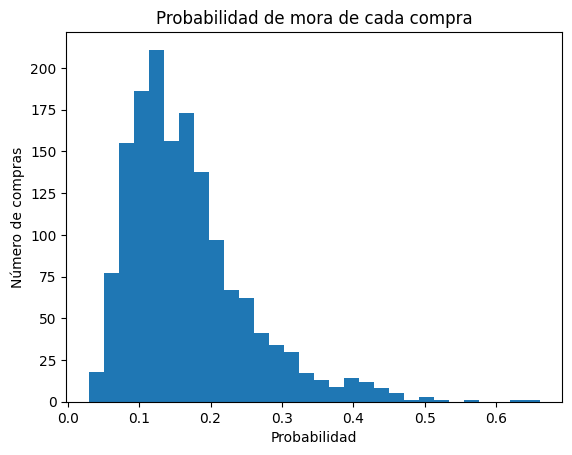

In [7]:
pd.Series(probabilidad).plot(
    kind="hist",
    bins=30,
    title="Probabilidad de mora de cada compra",
    xlabel="Probabilidad",
    ylabel="Número de compras",
)
plt.show()

Casi todas están por debajo de 0.5: el modelo rara vez está seguro de que habrá mora.

### Paso 4: el umbral

Para decidir, hay que elegir un **umbral**: desde qué probabilidad marcamos la venta. Es el mismo `=SI()` (`IF`) del inicio. Lo escribimos con una comparación, como en un filtro:

In [8]:
print((probabilidad >= 0.5).sum())
print((probabilidad >= 0.25).sum())

6
227


Con 0.5, solo marca 6 de 1,531 compras: casi nada que revisar. Con 0.25, marca 227. **El umbral no lo decide el modelo: lo decide el negocio**, según cuánto cuesta equivocarse. Lo veremos en el próximo episodio.

Y como las probabilidades ordenan las compras, también puedes usarlas sin umbral: *"revisa primero las de arriba, hasta donde alcance el equipo"*.

### Antes de usar algo así

- **Sirve para ordenar qué revisar, no para negar crédito automáticamente.** Una persona decide.
- **Hay un sesgo:** el modelo solo ve a quienes ya recibieron crédito. No sabe nada de los que fueron rechazados.
- **No lo uses para clientes nuevos:** casi todos los casos de prueba tienen historial, así que no sabemos cómo funciona con ellos.

En la Temporada 2 volveremos a este tema, en el episodio de ética.

## 🤖 Pídeselo a la IA

> *"Tengo un modelo que da la probabilidad de que una factura se pague tarde. Explícame, con ejemplos de oficina, qué significa una probabilidad de 0.3, y qué podría salir mal si la uso para rechazar clientes."*

La IA te ayuda a escribir y entender código, pero **tú debes entender lo que hace**. Revisa cada respuesta antes de usarla, y no pegues datos de tu empresa.

## ✅ Resumen

| En Excel | En Python |
|---|---|
| Una regla con `=SI()` (`IF`) | `make_pipeline(StandardScaler(), LogisticRegression())` |
| Calcular un puntaje de riesgo | `modelo.predict_proba(x)[:, 1]` |
| `=SI(puntaje>=0.25, ...)` (`IF`) | `probabilidad >= 0.25` |
| Entrenar solo con resultados conocidos ese día | `se_sabe <= corte`, dentro de `preparar_creditos` |

## 📝 Ahora te toca

Abre [el ejercicio en Colab](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-1/07-clasificacion-creditos/ejercicio.ipynb) y arma tu lista de revisión. Cuando termines, compara con [la solución](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-1/07-clasificacion-creditos/solucion.ipynb).

---

*Del Excel al Machine Learning* · por [Percy Nazario](https://www.linkedin.com/in/percy-nazario/) · [Repositorio](https://github.com/PercyTechX/del-excel-al-ml) · Contenido bajo licencia CC BY 4.0